In [76]:
import pandas as pd  
  
# Load the dataset  
df = pd.read_csv('./data/resale_transactions_categorised.csv')

In [77]:
df.head()

,id,month,flat_type,block,street_name,storey_range,floor_area_sqm,lease_commence_date,remaining_lease,town_id,flatm_id,town_name,flatm_name,price_category
0,1,2018-05,5 ROOM,118,PASIR RIS ST 11,07 TO 09,123.0,1989,70 years 03 months,17,5,PASIR RIS,Improved,Above Median
1,2,2016-10,4 ROOM,101,RIVERVALE WALK,01 TO 03,100.0,1999,81,21,8,SENGKANG,Model A,Below Median
2,3,2018-10,5 ROOM,688A,CHOA CHU KANG DR,19 TO 21,110.0,2002,82 years 06 months,9,5,CHOA CHU KANG,Improved,Below Median
3,4,2015-12,4 ROOM,130,LOR AH SOO,13 TO 15,103.0,1984,67,12,8,HOUGANG,Model A,Above Median
4,5,2017-09,5 ROOM,533,SERANGOON NTH AVE 4,07 TO 09,122.0,1992,74 years 02 months,22,5,SERANGOON,Improved,Above Median


In [78]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 88688 entries, 0 to 88687
Data columns (total 14 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   id                   88688 non-null  int64  
 1   month                88688 non-null  object 
 2   flat_type            88688 non-null  object 
 3   block                88688 non-null  object 
 4   street_name          88688 non-null  object 
 5   storey_range         88688 non-null  object 
 6   floor_area_sqm       88688 non-null  float64
 7   lease_commence_date  88688 non-null  int64  
 8   remaining_lease      88688 non-null  object 
 9   town_id              88688 non-null  int64  
 10  flatm_id             88688 non-null  int64  
 11  town_name            87905 non-null  object 
 12  flatm_name           88174 non-null  object 
 13  price_category       88688 non-null  object 
dtypes: float64(1), int64(4), object(9)
memory usage: 9.5+ MB


In [79]:
df.isnull().sum()

id                       0
month                    0
flat_type                0
block                    0
street_name              0
storey_range             0
floor_area_sqm           0
lease_commence_date      0
remaining_lease          0
town_id                  0
flatm_id                 0
town_name              783
flatm_name             514
price_category           0
dtype: int64

In [80]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,88688.0,42233.303739,24376.312037,1.0,21136.75,42228.5,63339.25,84465.0
floor_area_sqm,88688.0,97.520444,24.197379,31.0,76.00,96.0,112.00,280.0
lease_commence_date,88688.0,1570.225352,1226.315949,-2016.0,1980.00,1988.0,2000.00,2016.0
town_id,88688.0,14.631337,8.032285,1.0,8.00,15.0,22.00,26.0
flatm_id,88688.0,8.889185,3.906898,1.0,5.00,8.0,12.00,21.0


In [81]:
df.duplicated().sum()

4223

In [82]:
df[df.duplicated(keep=False)].sort_values(by=list(df.columns))

,id,month,flat_type,block,street_name,storey_range,floor_area_sqm,lease_commence_date,remaining_lease,town_id,flatm_id,town_name,flatm_name,price_category
103,104,2016-09,3 ROOM,201E,TAMPINES ST 23,04 TO 06,68.0,-1987,70,23,12,TAMPINES,New Generation,Below Median
88570,104,2016-09,3 ROOM,201E,TAMPINES ST 23,04 TO 06,68.0,-1987,70,23,12,TAMPINES,New Generation,Below Median
106,107,2015-08,4 ROOM,146,SERANGOON NTH AVE 1,13 TO 15,83.0,-1987,70,22,17,SERANGOON,Simplified,Below Median
88156,107,2015-08,4 ROOM,146,SERANGOON NTH AVE 1,13 TO 15,83.0,-1987,70,22,17,SERANGOON,Simplified,Below Median
114,115,2017-03,4 ROOM,274D,PUNGGOL PL,16 TO 18,93.0,2013,95 years 04 months,18,13,PUNGGOL,Premium Apartment,Above Median
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
87372,84427,2019-01,5 ROOM,348D,YISHUN AVE 11,13 TO 15,112.0,2013,93 years 09 months,26,4,YISHUN,DBSS,Above Median
84428,84429,2018-10,4 ROOM,838,HOUGANG CTRL,04 TO 06,100.0,-1997,77 years 05 months,12,8,HOUGANG,Model A,Above Median
85835,84429,2018-10,4 ROOM,838,HOUGANG CTRL,04 TO 06,100.0,-1997,77 years 05 months,12,8,HOUGANG,Model A,Above Median
84461,84462,2015-06,5 ROOM,596A,ANG MO KIO ST 52,07 TO 09,110.0,2002,86,1,5,ANG MO KIO,Improved,Above Median


In [83]:
df.drop_duplicates(inplace=True)

Creating Bar Chart
---------

In [84]:
import seaborn as sns
import matplotlib.pyplot as plt

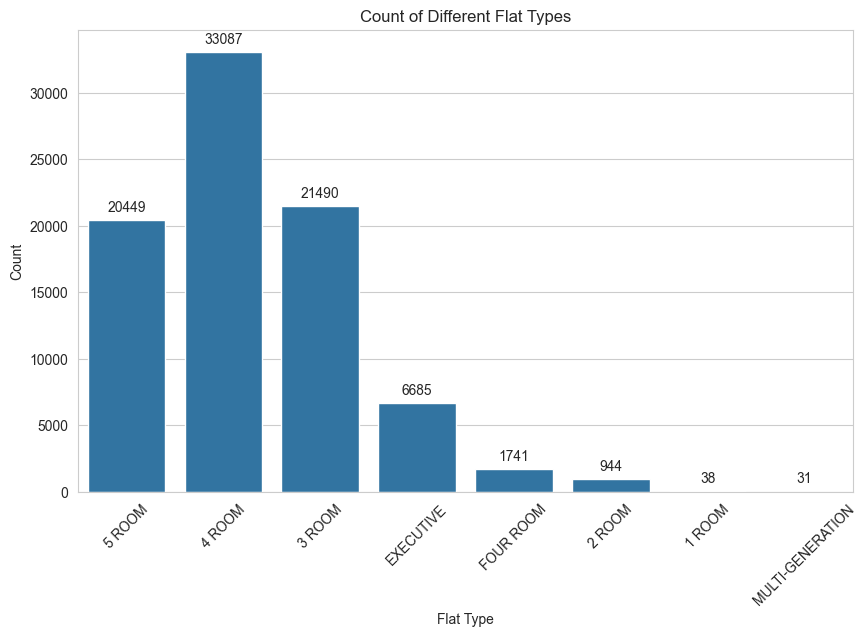

In [85]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Bar chart for flat type with annotations
plt.figure(figsize=(10, 6))
count_plot = sns.countplot(x='flat_type', data=df)
plt.title('Count of Different Flat Types')
plt.xlabel('Flat Type')
plt.ylabel('Count')
plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha = 'center', va = 'center',
                        xytext = (0, 9),
                        textcoords = 'offset points')

plt.show()

In [86]:
# Replace 'FOUR ROOM' with '4 ROOM' in the 'flat_type' column
df['flat_type'] = df['flat_type'].replace('FOUR ROOM', '4 ROOM')
  
# Verify the changes
print(df['flat_type'].value_counts())

flat_type
4 ROOM              34828
3 ROOM              21490
5 ROOM              20449
EXECUTIVE            6685
2 ROOM                944
1 ROOM                 38
MULTI-GENERATION       31
Name: count, dtype: int64


Creating Histogram
------------------

C:\Users\wongj\AppData\Local\Temp\ipykernel_24068\1792947088.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  count_plot = sns.countplot(x='price_category', data=df, palette='pastel')


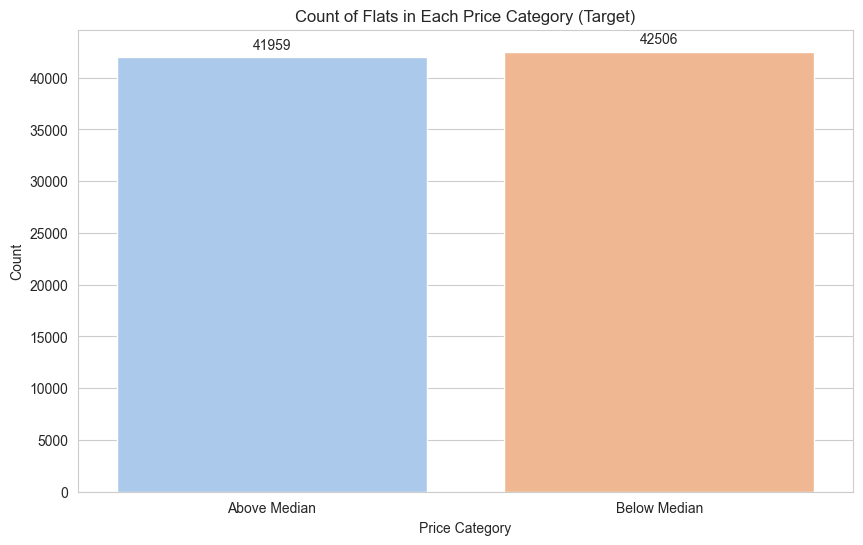

In [87]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Bar chart for price category with annotations
plt.figure(figsize=(10, 6))
count_plot = sns.countplot(x='price_category', data=df, palette='pastel')
plt.title('Count of Flats in Each Price Category (Target)')
plt.xlabel('Price Category')
plt.ylabel('Count')
#plt.xticks(rotation=45)

# Annotate the bars with the frequency count
for p in count_plot.patches:
    count_plot.annotate(format(p.get_height(), '.0f'),
                        (p.get_x() + p.get_width() / 2., p.get_height()),
                        ha = 'center', va = 'center',
                        xytext = (0, 9),
                        textcoords = 'offset points')

plt.show()

Creating Line Chart
-------------------

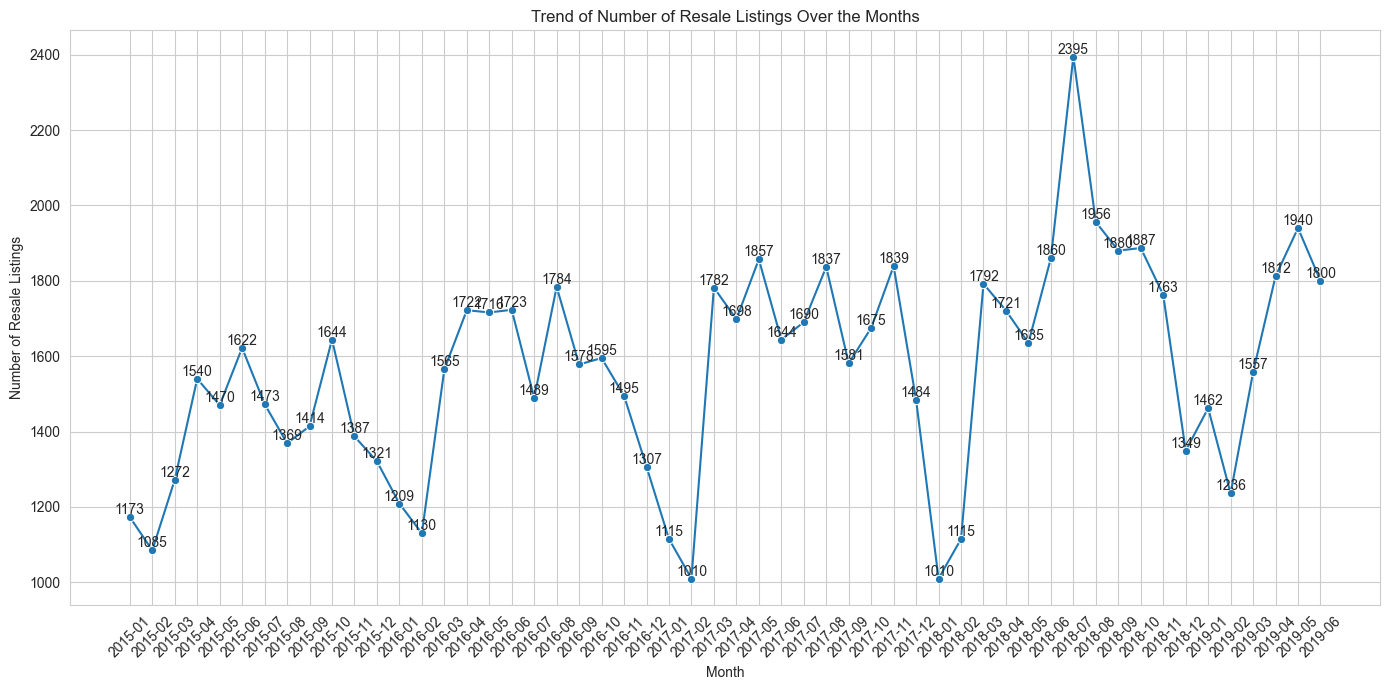

In [88]:
# Set Aesthetic Style
sns.set_style("whitegrid")

# Count the Number of Listings by Month
month_counts = df['month'].value_counts().sort_index()

# Create the Line Chart
plt.figure(figsize=(14, 7))
line_plot = sns.lineplot(x=month_counts.index, y=month_counts.values, marker='o')

# Annotate the Data Points
for x, y in zip(month_counts.index, month_counts.values):
    plt.text(x, y, f'{y}', ha='center', va='bottom')

# Label the Chart
plt.title('Trend of Number of Resale Listings Over the Months')
plt.xlabel('Month')
plt.ylabel('Number of Resale Listings')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Creating Subplot Bar Charts
---------------------------

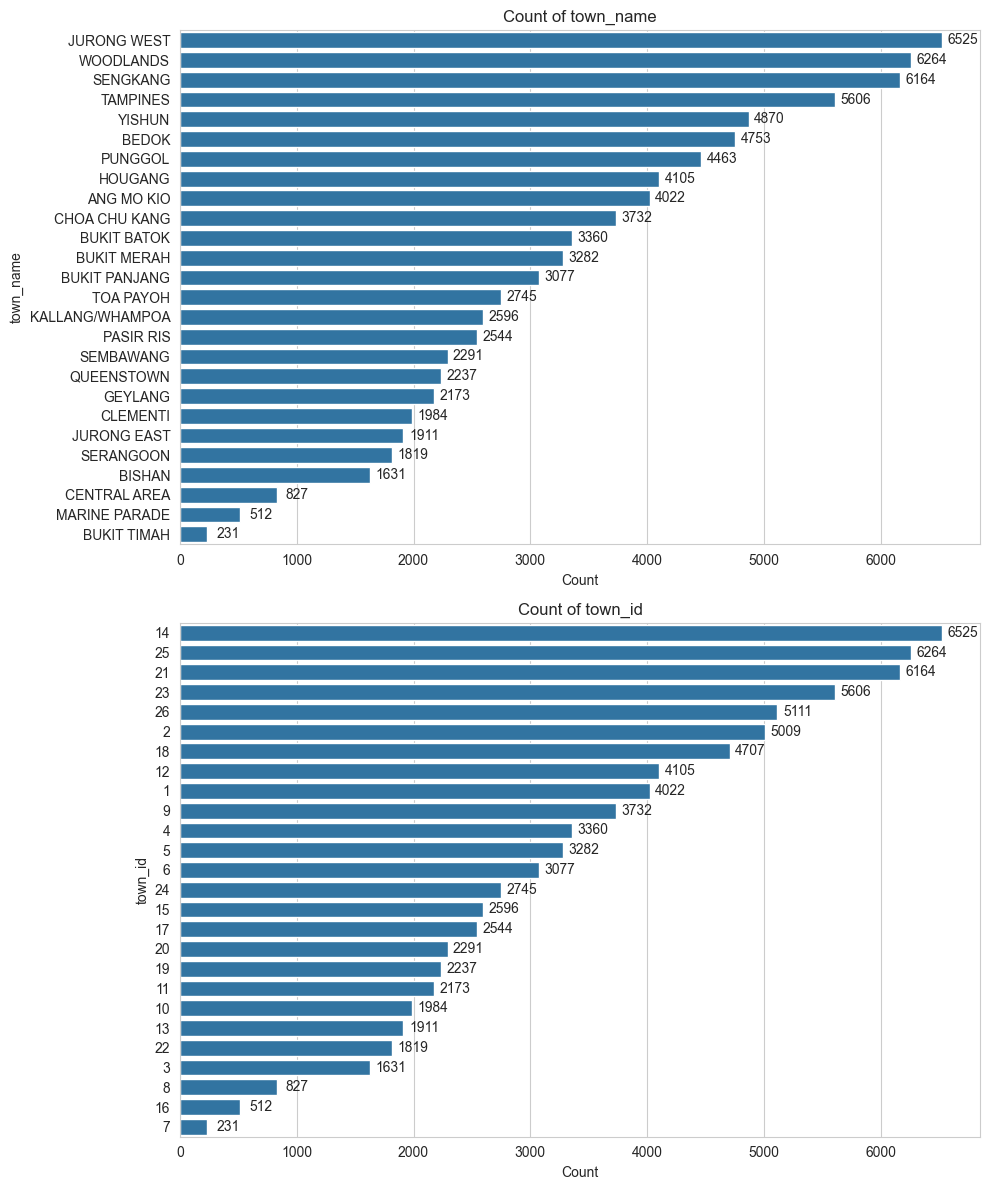

In [89]:
# Set the aesthetic style of the plots
sns.set_style("whitegrid")

# Create a figure with 2 subplots (one above the other)
fig, axes = plt.subplots(2, 1, figsize=(10, 12))

# Sort the town_name by count
sorted_town_name = df['town_name'].value_counts().index

# Count plot for town_name with annotations
count_plot_1 = sns.countplot(y='town_name', data=df, order=sorted_town_name, ax=axes[0])
axes[0].set_title('Count of town_name')
axes[0].set_xlabel('Count')
axes[0].set_ylabel('town_name')

# Annotate the bars with the frequency count
for p in count_plot_1.patches:
    count_plot_1.annotate(format(p.get_width(), '.0f'),
                          (p.get_width(), p.get_y() + p.get_height() / 2),
                          ha='center', va='center',
                          xytext=(15, 0),
                          textcoords='offset points')

# Sort the town_id by count
sorted_town_id = df['town_id'].value_counts().index

# Count plot for town_id with annotations
count_plot_2 = sns.countplot(y='town_id', data=df, order=sorted_town_id, ax=axes[1])
axes[1].set_title('Count of town_id')
axes[1].set_xlabel('Count')
axes[1].set_ylabel('town_id')

# Annotate the bars with the frequency count
for p in count_plot_2.patches:
    count_plot_2.annotate(format(p.get_width(), '.0f'),
                          (p.get_width(), p.get_y() + p.get_height() / 2),
                          ha='center', va='center',
                          xytext=(15, 0),
                          textcoords='offset points')

# Adjust layout to prevent overlap
plt.tight_layout()

# Show the combined plot
plt.show()

In [90]:
# Absolute negative years values
df['lease_commence_date'] = df['lease_commence_date'].abs()
# Replace 'FOUR ROOM' with '4 ROOM' in the 'flat_type' column  
df['flat_type'] = df['flat_type'].replace('FOUR ROOM', '4 ROOM')


In [91]:
def fill_missing_names(df: pd.DataFrame, id_column: str, name_column: str) -> pd.DataFrame:
    """
    Fills missing values in the 'name_column' using the 'id_column'.

    Args:
        df (pd.DataFrame): The DataFrame containing the columns to be filled.
        id_column (str): The name of the column containing the IDs.
        name_column (str): The name of the column containing the names to be filled.

    Returns:
        pd.DataFrame: The DataFrame with missing values in 'name_column' filled.
    """
    # Identify missing values in the 'name_column'
    missing_names = df[name_column].isna()

    # Create a dictionary mapping 'id_column' to 'name_column'
    name_mapping = df[[id_column, name_column]].dropna().drop_duplicates().set_index(id_column)[name_column].to_dict()

    # Fill missing 'name_column' using the mapping
    df.loc[missing_names, name_column] = df.loc[missing_names, id_column].map(name_mapping)

    return df

In [92]:
# Fill missing values in 'town_name' column
df = fill_missing_names(df=df, id_column='town_id', name_column='town_name')

# Fill missing values in 'flatm_name' column
df = fill_missing_names(df=df, id_column='flatm_id', name_column='flatm_name')

In [93]:
df.drop_duplicates(inplace=True)

In [94]:
# Drop irrelevant features
df = df.drop(columns=['id', 'town_id', 'flatm_id'])

In [95]:
# Convert 'month' column to datetime
df['year_month'] = pd.to_datetime(df['month'], format='%Y-%m')

# Extract year and month from the datetime object
df['year'] = df['year_month'].dt.year
df['month'] = df['year_month'].dt.month

df.head()

,month,flat_type,block,street_name,storey_range,floor_area_sqm,lease_commence_date,remaining_lease,town_name,flatm_name,price_category,year_month,year
0,5,5 ROOM,118,PASIR RIS ST 11,07 TO 09,123.0,1989,70 years 03 months,PASIR RIS,Improved,Above Median,2018-05-01,2018
1,10,4 ROOM,101,RIVERVALE WALK,01 TO 03,100.0,1999,81,SENGKANG,Model A,Below Median,2016-10-01,2016
2,10,5 ROOM,688A,CHOA CHU KANG DR,19 TO 21,110.0,2002,82 years 06 months,CHOA CHU KANG,Improved,Below Median,2018-10-01,2018
3,12,4 ROOM,130,LOR AH SOO,13 TO 15,103.0,1984,67,HOUGANG,Model A,Above Median,2015-12-01,2015
4,9,5 ROOM,533,SERANGOON NTH AVE 4,07 TO 09,122.0,1992,74 years 02 months,SERANGOON,Improved,Above Median,2017-09-01,2017


In [96]:
# drop year_month
df = df.drop(columns=['year_month'])

In [97]:
import re

def extract_lease_info(lease_str: str) -> int:
    """
    Convert lease information from a string format to total months.

    This function takes a string representing the remaining lease period, which
    may include years and months in various formats (e.g., "70 years 3 months",
    "85 years", "67"), and converts it to the total number of months.

    Args:
        lease_str (str): The remaining lease period as a string.

    Returns:
        int: The total number of months, or None if the input is NaN.
    """

    if pd.isna(lease_str):
        return None
    
    # Regular expression to extract years and months
    years_match = re.search(r'(\d+)\s*years?', lease_str)
    months_match = re.search(r'(\d+)\s*months?', lease_str)
    number_match = re.match(r'^\d+$', lease_str.strip())
    
    if years_match:
        years = int(years_match.group(1))
    elif number_match:  # If only a number is present, assume it's in years
        years = int(number_match.group(0))
    else:
        years = 0
        
    months = int(months_match.group(1)) if months_match else 0
    
    # Convert the total lease period to months
    total_months = years * 12 + months
    return total_months

In [98]:
# Extract lease information  
df['remaining_lease_months'] = df['remaining_lease'].apply(extract_lease_info) 
# Display a random sample of the data to check the transformation
df[['remaining_lease', 'remaining_lease_months']].sample(5)

,remaining_lease,remaining_lease_months
72977,63 years 06 months,762
77993,86 years 04 months,1036
10402,70 years 07 months,847
82430,86,1032
74790,84,1008


In [99]:
# Drop the 'remaining_lease' column
df = df.drop(columns=['remaining_lease'])

In [100]:
# Function to convert storey_range to ordinal scale by taking the average of the range
def convert_storey_range(storey_range: str) -> float:
    """
    Converts a storey range string into its average numerical value.
    
    The function takes a storey range in the format 'XX TO YY', splits it into two parts,
    converts these parts to integers, and returns the average of these integers.
    
    Args:
        storey_range (str): A string representing a range of storeys, in the format 'XX TO YY'.
        
    Returns:
        float: The average value of the two storeys in the range.
        
    Example:
        convert_storey_range('07 TO 09') -> 8.0
    """
    range_values = storey_range.split(' TO ')
    return (int(range_values[0]) + int(range_values[1])) / 2

# Use the .apply() method to convert the 'storey_range' column with the function
df['storey_range'] = df['storey_range'].apply(convert_storey_range)

In [101]:
# Drop the 'block' and 'street_name' columns
df = df.drop(columns=['block', 'street_name'])

### Preparing the classification Target Variable

In [102]:
# Encode the target column
df['price_category'] = df['price_category'].map({'Above Median': 1, 'Below Median': 0})

# Check the distribution of the target column
df['price_category'].value_counts()

price_category
0    42506
1    41959
Name: count, dtype: int64

In [103]:
from sklearn.model_selection import train_test_split

# Separate the data into features and target
X = df.drop(columns='price_category')
y = df['price_category']

# Split the data into training (80%) and test-validation (20%) sets
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Split the test-validation set (20%) into validation (10%) and test (10%) sets
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

In [104]:
# Display the shapes of the splits to verify
print("Training set shape:", X_train.shape, y_train.shape)
print("Validation set shape:", X_val.shape, y_val.shape)
print("Test set shape:", X_test.shape, y_test.shape)

Training set shape: (67572, 9) (67572,)
Validation set shape: (8446, 9) (8446,)
Test set shape: (8447, 9) (8447,)


In [105]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Define numerical features to be standardized
numerical_features = ['floor_area_sqm', 'remaining_lease_months', 'lease_commence_date', 'year']

# Create a numerical transformer pipeline
numerical_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

## Feature Encoding

In [106]:
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

# Define nomial features to be one-hot encoded
nominal_features = ['month', 'town_name', 'flatm_name']

# Define ordinal features to be ordinally encoded
ordinal_features = ['flat_type']

# Define the ordinal categories for flat_type
flat_type_categories = ['1 ROOM', '2 ROOM', '3 ROOM', '4 ROOM', '5 ROOM', 'MULTI-GENERATION', 'EXECUTIVE']

# Define passthrough features that will not be transformed
passthrough_features = ['storey_range']

# Create a nominal transformer pipeline
nominal_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

# Create an ordinal transformer pipeline
ordinal_transformer = Pipeline(steps=[
    ('ordinal', OrdinalEncoder(categories=[flat_type_categories], handle_unknown='use_encoded_value', unknown_value=-1))  
])

In [107]:
from sklearn.compose import ColumnTransformer

# Combine transformers into a single ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('nom', nominal_transformer, nominal_features),
        ('ord', ordinal_transformer, ordinal_features),
        ('pass', 'passthrough', passthrough_features) # Pass through the storey_range feature without transformation
    ],
    remainder='passthrough',
    n_jobs=-1
    )

## Logistic Regression

In [108]:
# Import the necessary library
from sklearn.linear_model import LogisticRegression

# Create the pipeline with a logistic regression model
logreg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),  # Use the preprocessor pipeline defined earlier
    ('classifier', LogisticRegression(max_iter=1000))
])

# Fit the pipeline to the training data
logreg_pipeline.fit(X_train, y_train)

# Predict on the validation set
y_val_pred = logreg_pipeline.predict(X_val)

In [109]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Calculate the classification metrics for Logistic Regression
logreg_val_accuracy = accuracy_score(y_val, y_val_pred)

# Display the metrics for Logistic Regression
print("Logistic Regression Metrics:")
print(f'LogReg Validation Accuracy: {logreg_val_accuracy:.5f}')

Logistic Regression Metrics:
LogReg Validation Accuracy: 0.89202


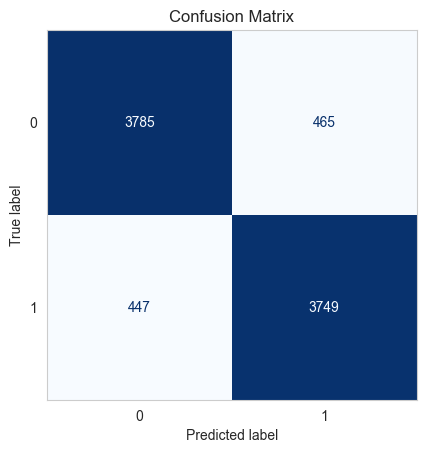

In [110]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Calculate the confusion matrix
cm = confusion_matrix(y_val, y_val_pred)

# Display the confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
fig, ax = plt.subplots()
disp.plot(cmap=plt.cm.Blues, ax=ax, colorbar=False)
plt.title("Confusion Matrix")
plt.grid(False)
plt.show()

In [111]:
# Calculate the classification metrics for Logistic Regression
logreg_val_precision = precision_score(y_val, y_val_pred)
logreg_val_recall = recall_score(y_val, y_val_pred)
logreg_val_f1 = f1_score(y_val, y_val_pred)

# Display the metrics for Logistic Regression
print("Logistic Regression Metrics:")
print(f'LogReg Validation Precision: {logreg_val_precision:.5f}')
print(f'LogReg Validation Recall: {logreg_val_recall:.5f}')
print(f'LogReg Validation F1 Score: {logreg_val_f1:.5f}')

Logistic Regression Metrics:
LogReg Validation Precision: 0.88965
LogReg Validation Recall: 0.89347
LogReg Validation F1 Score: 0.89156


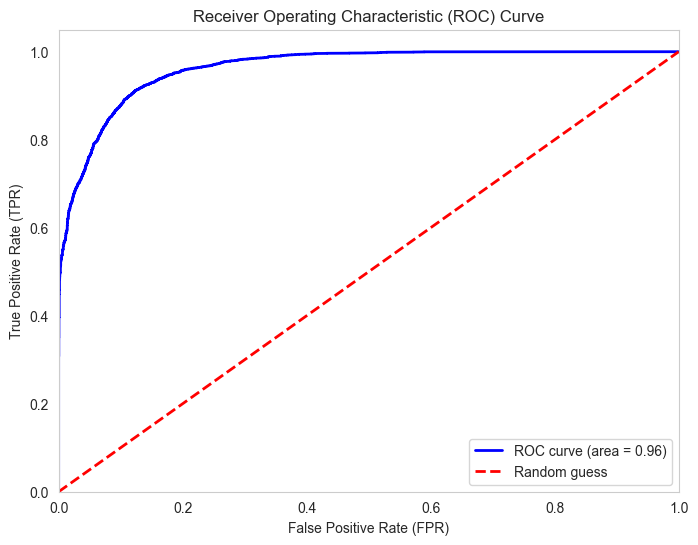

In [112]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt  

# Calculate the ROC curve
fpr, tpr, thresholds = roc_curve(y_val, logreg_pipeline.predict_proba(X_val)[:, 1])

# Calculate the AUC
roc_auc = roc_auc_score(y_val, logreg_pipeline.predict_proba(X_val)[:, 1])

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')  
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--', label='Random guess')  
plt.xlim([0.0, 1.0])  
plt.ylim([0.0, 1.05])  
plt.xlabel('False Positive Rate (FPR)')  
plt.ylabel('True Positive Rate (TPR)')  
plt.title('Receiver Operating Characteristic (ROC) Curve')  
plt.legend(loc='lower right')  
plt.grid()  
plt.show()

## KNN

In [113]:
from sklearn.neighbors import KNeighborsClassifier

# Create the pipeline with a KNN classifier
knn_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor), # Use the preprocessor pipeline defined earlier
    ('classifier', KNeighborsClassifier(n_neighbors=5)) # You can choose the number of neighbors (k) as desired
])

# Fit the pipeline to the training data
knn_pipeline.fit(X_train, y_train)

# Predict on the validation set
y_val_pred = knn_pipeline.predict(X_val)
y_val_pred_proba = knn_pipeline.predict_proba(X_val)[:, 1]

In [114]:
# Calculate and print the classification metrics for the KNN model
val_accuracy = accuracy_score(y_val, y_val_pred)
val_precision = precision_score(y_val, y_val_pred)
val_recall = recall_score(y_val, y_val_pred)
val_f1 = f1_score(y_val, y_val_pred)
val_roc_auc = roc_auc_score(y_val, y_val_pred_proba)

print("K-Nearest Neighbors (KNN) Metrics:")
print(f'Validation Accuracy: {val_accuracy:.5f}')
print(f'Validation Precision: {val_precision:.5f}')  
print(f'Validation Recall: {val_recall:.5f}')  
print(f'Validation F1 Score: {val_f1:.5f}')  
print(f'Validation ROC AUC: {val_roc_auc:.5f}')

K-Nearest Neighbors (KNN) Metrics:
Validation Accuracy: 0.87521
Validation Precision: 0.88094
Validation Recall: 0.86582
Validation F1 Score: 0.87332
Validation ROC AUC: 0.94058


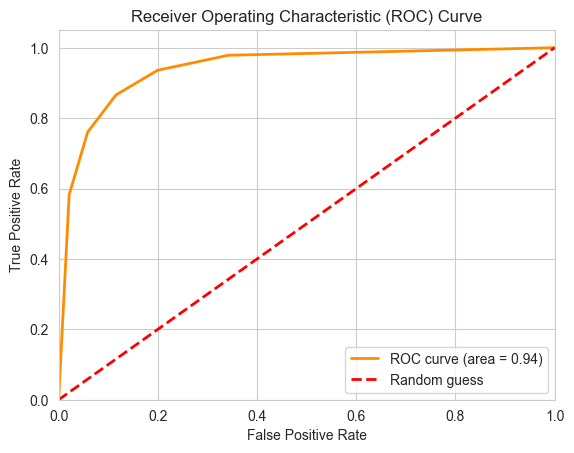

In [115]:
# Plot the ROC curve
fpr, tpr, thresholds = roc_curve(y_val, knn_pipeline.predict_proba(X_val)[:, 1])
roc_auc = roc_auc_score(y_val, knn_pipeline.predict_proba(X_val)[:, 1])

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')  
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--', label='Random guess')  
plt.xlim([0.0, 1.0])  
plt.ylim([0.0, 1.05])  
plt.xlabel('False Positive Rate')  
plt.ylabel('True Positive Rate')  
plt.title('Receiver Operating Characteristic (ROC) Curve')  
plt.legend(loc="lower right")  
plt.grid(True)  
plt.show()

## Decision tree

In [116]:
from sklearn.tree import DecisionTreeClassifier

# Create the pipeline with a Decision Tree classifier
dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(criterion='gini', min_samples_split=2, max_depth=None, random_state=42))  
])

# Fit the pipeline to the training data
dt_pipeline.fit(X_train, y_train)

# Predict on the validation set
y_val_pred = dt_pipeline.predict(X_val)
y_val_pred_proba = dt_pipeline.predict_proba(X_val)[:, 1]

# Calculate metrics for the validation set
val_accuracy = accuracy_score(y_val, y_val_pred)
val_precision = precision_score(y_val, y_val_pred)  
val_recall = recall_score(y_val, y_val_pred)  
val_f1 = f1_score(y_val, y_val_pred)  
val_roc_auc = roc_auc_score(y_val, y_val_pred_proba)  

# Calculate metrics for the training set
y_train_pred = dt_pipeline.predict(X_train)  
y_train_pred_proba = dt_pipeline.predict_proba(X_train)[:, 1]  

train_accuracy = accuracy_score(y_train, y_train_pred)  
train_precision = precision_score(y_train, y_train_pred)  
train_recall = recall_score(y_train, y_train_pred)  
train_f1 = f1_score(y_train, y_train_pred)  
train_roc_auc = roc_auc_score(y_train, y_train_pred_proba)  

print("Decision Tree Classifier Validation Metrics:")
print(f'Validation Accuracy: {val_accuracy:.5f}')
print(f'Validation Precision: {val_precision:.5f}')  
print(f'Validation Recall: {val_recall:.5f}')  
print(f'Validation F1 Score: {val_f1:.5f}')  
print(f'Validation ROC AUC: {val_roc_auc:.5f}')  

print("Training Set Metrics:")
print(f'Training Accuracy: {train_accuracy:.5f}')  
print(f'Training Precision: {train_precision:.5f}')  
print(f'Training Recall: {train_recall:.5f}')  
print(f'Training F1 Score: {train_f1:.5f}')  
print(f'Training ROC AUC: {train_roc_auc:.5f}')

Decision Tree Classifier Validation Metrics:
Validation Accuracy: 0.90126
Validation Precision: 0.89948
Validation Recall: 0.90205
Validation F1 Score: 0.90076
Validation ROC AUC: 0.90279
Training Set Metrics:
Training Accuracy: 0.99593
Training Precision: 0.99922
Training Recall: 0.99258
Training F1 Score: 0.99589
Training ROC AUC: 0.99997


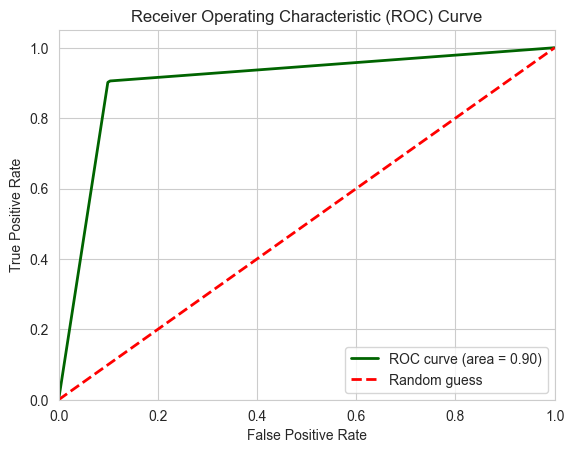

In [117]:
fpr, tpr, thresholds = roc_curve(y_val, y_val_pred_proba)
roc_auc = roc_auc_score(y_val, y_val_pred_proba)

plt.figure()  
plt.plot(fpr, tpr, color='darkgreen', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')  
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--', label='Random guess')  
plt.xlim([0.0, 1.0])  
plt.ylim([0.0, 1.05])  
plt.xlabel('False Positive Rate')  
plt.ylabel('True Positive Rate')  
plt.title('Receiver Operating Characteristic (ROC) Curve')  
plt.legend(loc="lower right")  
plt.grid(True)  
plt.show()

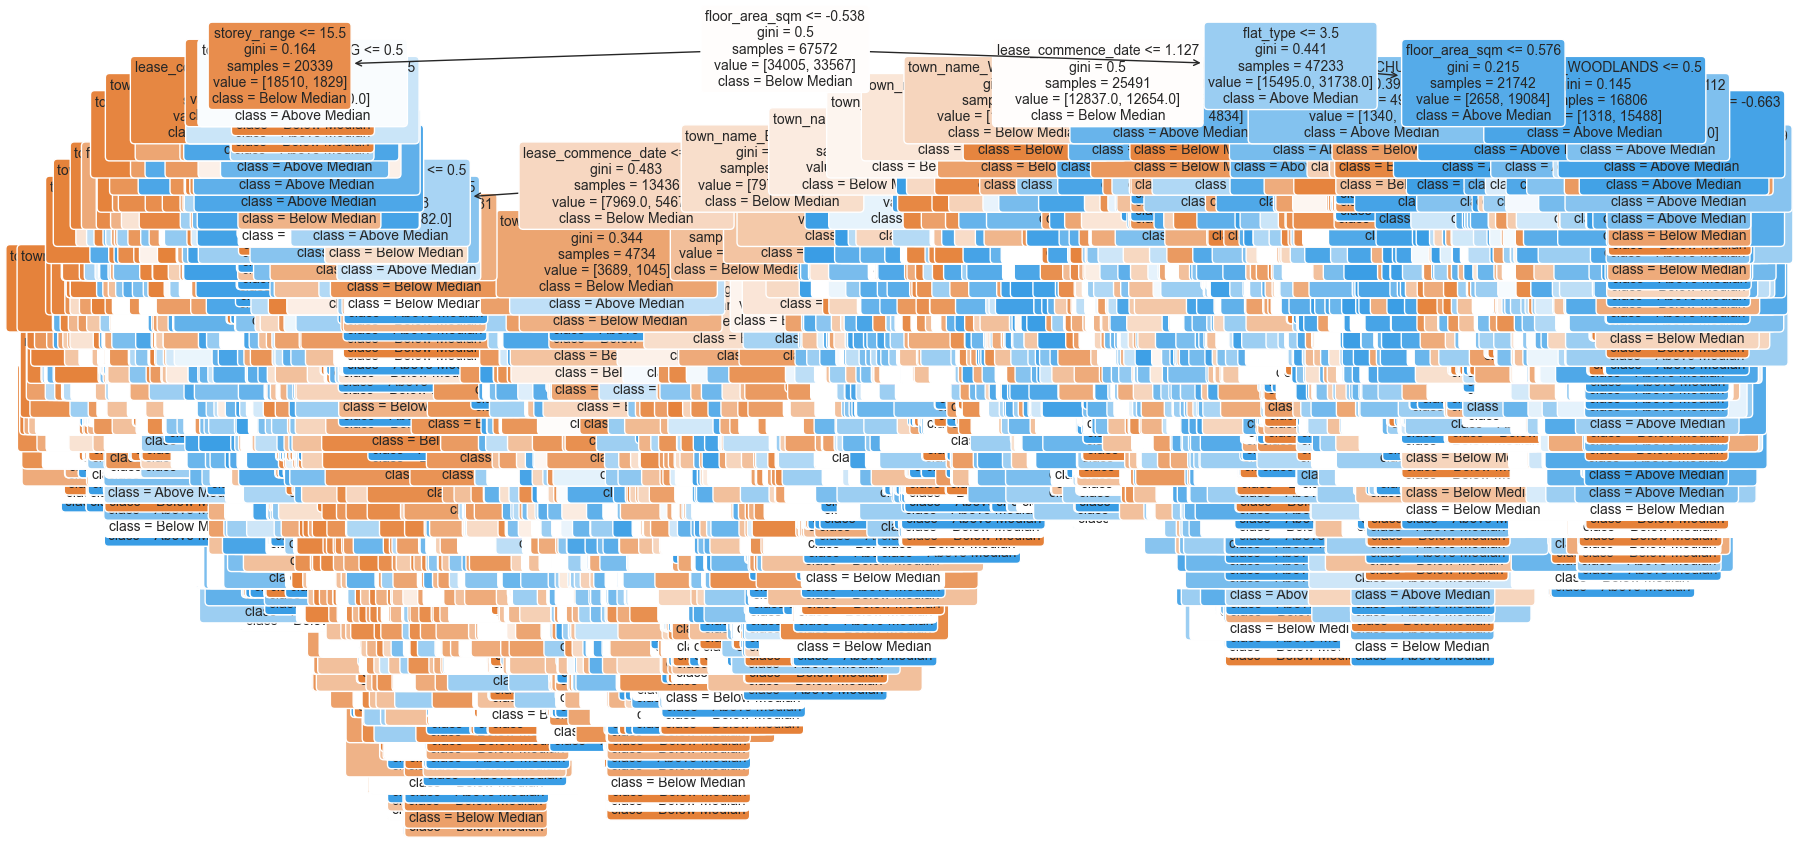

In [118]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Extract the transformed feature names
feature_names = []
for name, transformer, columns in dt_pipeline.named_steps['preprocessor'].transformers_:
    if hasattr(transformer, 'named_steps'):
        for step in transformer.named_steps.values():
            if hasattr(step, 'get_feature_names_out'):
                feature_names.extend(step.get_feature_names_out(columns))
    elif hasattr(transformer, 'get_feature_names_out'):
        feature_names.extend(transformer.get_feature_names_out(columns))
    else:
        feature_names.extend(columns)
				
# Plot the decision tree
plt.figure(figsize=(20, 10))
plot_tree(dt_pipeline.named_steps['classifier'], feature_names=feature_names, class_names=['Below Median', 'Above Median'], filled=True, rounded=True, fontsize=10)
plt.show()

### Pruning

In [119]:
# Create the new pipeline with a Decision Tree classifier with new max_depth pre-pruning parameter
dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(criterion='gini', min_samples_split=2, max_depth=5, min_samples_leaf=1, random_state=42))
])  

# Fit the pipeline to the training data
dt_pipeline.fit(X_train, y_train)

# Predict on the validation set
y_val_pred = dt_pipeline.predict(X_val)
y_val_pred_proba = dt_pipeline.predict_proba(X_val)[:, 1]

# Calculate metrics for the validation set
val_accuracy = accuracy_score(y_val, y_val_pred)
val_precision = precision_score(y_val, y_val_pred)  
val_recall = recall_score(y_val, y_val_pred)  
val_f1 = f1_score(y_val, y_val_pred)  
val_roc_auc = roc_auc_score(y_val, y_val_pred_proba)  

# Calculate metrics for the training set
y_train_pred = dt_pipeline.predict(X_train)  
y_train_pred_proba = dt_pipeline.predict_proba(X_train)[:, 1]  

train_accuracy = accuracy_score(y_train, y_train_pred)  
train_precision = precision_score(y_train, y_train_pred)  
train_recall = recall_score(y_train, y_train_pred)  
train_f1 = f1_score(y_train, y_train_pred)  
train_roc_auc = roc_auc_score(y_train, y_train_pred_proba)  

print("Decision Tree Classifier Validation Metrics:")
print(f'Validation Accuracy: {val_accuracy:.5f}')
print(f'Validation Precision: {val_precision:.5f}')  
print(f'Validation Recall: {val_recall:.5f}')  
print(f'Validation F1 Score: {val_f1:.5f}')  
print(f'Validation ROC AUC: {val_roc_auc:.5f}')  

print("Training Set Metrics:")
print(f'Training Accuracy: {train_accuracy:.5f}')  
print(f'Training Precision: {train_precision:.5f}')  
print(f'Training Recall: {train_recall:.5f}')  
print(f'Training F1 Score: {train_f1:.5f}')  
print(f'Training ROC AUC: {train_roc_auc:.5f}')

Decision Tree Classifier Validation Metrics:
Validation Accuracy: 0.81660
Validation Precision: 0.88846
Validation Recall: 0.72140
Validation F1 Score: 0.79626
Validation ROC AUC: 0.90967
Training Set Metrics:
Training Accuracy: 0.81654
Training Precision: 0.89024
Training Recall: 0.71937
Training F1 Score: 0.79574
Training ROC AUC: 0.91047


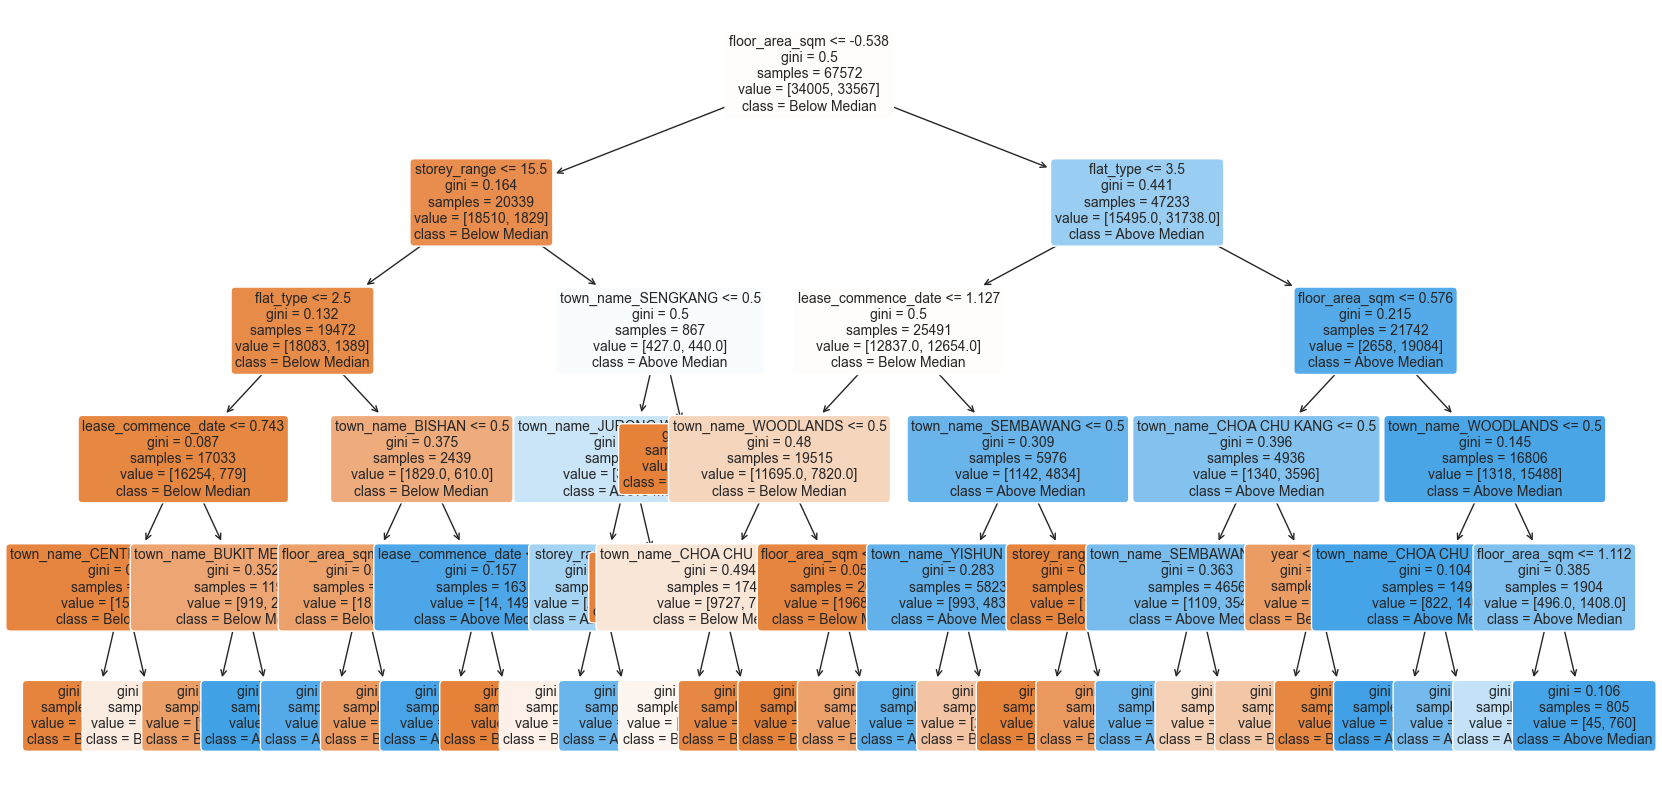

In [120]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Extract the transformed feature names
feature_names = []
for name, transformer, columns in dt_pipeline.named_steps['preprocessor'].transformers_:
    if hasattr(transformer, 'named_steps'):
        for step in transformer.named_steps.values():
            if hasattr(step, 'get_feature_names_out'):
                feature_names.extend(step.get_feature_names_out(columns))
    elif hasattr(transformer, 'get_feature_names_out'):
        feature_names.extend(transformer.get_feature_names_out(columns))
    else:
        feature_names.extend(columns)
				
# Plot the decision tree
plt.figure(figsize=(20, 10))
plot_tree(dt_pipeline.named_steps['classifier'], feature_names=feature_names, class_names=['Below Median', 'Above Median'], filled=True, rounded=True, fontsize=10)
plt.show()

In [135]:
from sklearn.model_selection import GridSearchCV

logreg_param_grid = {
    'classifier__C': [0.001, 0.01, 0.1, 1.0, 10, 100, 1000],
    'classifier__penalty': ['l2', None]
}

logreg_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),  # Use the preprocessor pipeline defined earlier
    ('classifier', LogisticRegression(max_iter=1000))
])

knn_param_grid = {
    'classifier__n_neighbors': [3, 5, 7, 9, 11, 15],
    'classifier__weights': ['uniform', 'distance']
}

knn_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor), # Use the preprocessor pipeline defined earlier
    ('classifier', KNeighborsClassifier()) # You can choose the number of neighbors (k) as desired
])

dt_param_grid = {
    'classifier__max_depth': [3, 5, 7, 10],
    'classifier__min_samples_split': [2, 5, 10],
    'classifier__min_samples_leaf': [1, 2, 4]
}

dt_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(criterion='gini', min_samples_split=2, min_samples_leaf=1, random_state=42))
])
# Perform grid search with cross-validation
logreg_grid_search = GridSearchCV(logreg_pipeline, logreg_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
logreg_grid_search.fit(X_train, y_train)

knn_grid_search = GridSearchCV(knn_pipeline, knn_param_grid, cv=5, scoring='accuracy', n_jobs=2)
knn_grid_search.fit(X_train, y_train)

dt_grid_search = GridSearchCV(dt_pipeline, dt_param_grid, cv=5, scoring='accuracy', n_jobs=-1)
dt_grid_search.fit(X_train, y_train)

c:\Users\wongj\miniconda3\envs\myenv\Lib\site-packages\sklearn\linear_model\_logistic.py:1186: UserWarning: Setting penalty=None will ignore the C and l1_ratio parameters
  warnings.warn(


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('preprocessor',
                                        ColumnTransformer(n_jobs=-1,
                                                          remainder='passthrough',
                                                          transformers=[('num',
                                                                         Pipeline(steps=[('scaler',
                                                                                          StandardScaler())]),
                                                                         ['floor_area_sqm',
                                                                          'remaining_lease_months',
                                                                          'lease_commence_date',
                                                                          'year']),
                                                                        ('nom',
                                                                         Pipeline(steps=[('onehot',
                                                                                          OneHotEncoder(handle_unknown='ignore'))]),
                                                                         ['month',
                                                                          'town_name',
                                                                          '...
                                                                                                                      'MULTI-GENERATION',
                                                                                                                      'EXECUTIVE']],
                                                                                                         handle_unknown='use_encoded_value',
                                                                                                         unknown_value=-1))]),
                                                                         ['flat_type']),
                                                                        ('pass',
                                                                         'passthrough',
                                                                         ['storey_range'])])),
                                       ('classifier',
                                        DecisionTreeClassifier(random_state=42))]),
             n_jobs=-1,
             param_grid={'classifier__max_depth': [3, 5, 7, 10],
                         'classifier__min_samples_leaf': [1, 2, 4],
                         'classifier__min_samples_split': [2, 5, 10]},
             scoring='accuracy')

In [138]:
for name, gs in [('Logistic Regression', logreg_grid_search),
                 ('KNN', knn_grid_search),
                 ('Decision Tree', dt_grid_search)]:
    print(f"{name}\n  Best params: {gs.best_params_}\n  Best CV score: {gs.best_score_:.4f}\n")

Logistic Regression
  Best params: {'classifier__C': 0.001, 'classifier__penalty': None}
  Best CV score: 0.8920

KNN
  Best params: {'classifier__n_neighbors': 15, 'classifier__weights': 'distance'}
  Best CV score: 0.8801

Decision Tree
  Best params: {'classifier__max_depth': 10, 'classifier__min_samples_leaf': 4, 'classifier__min_samples_split': 10}
  Best CV score: 0.8768



K-Nearest Neighbors (KNN) Metrics:
Validation Accuracy: 0.89238
Validation Precision: 0.89010
Validation Recall: 0.89371
Validation F1 Score: 0.89190
Validation ROC AUC: 0.96232


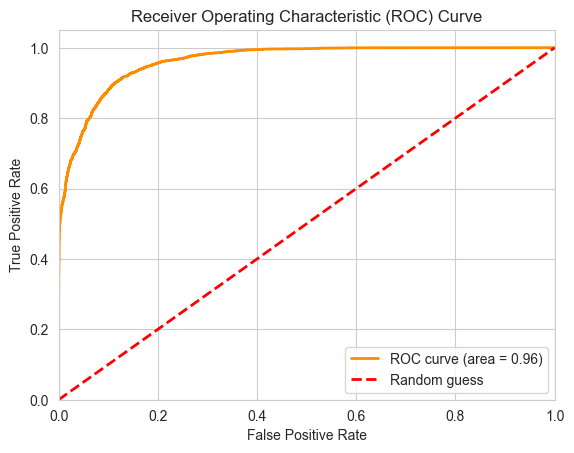

In [ ]:
# Evaluate the best Logistic Regression model on the validation set
best_logreg_model = logreg_grid_search.best_estimator_
y_val_pred_logreg = best_logreg_model.predict(X_val)
y_val_pred_proba_logreg = best_logreg_model.predict_proba(X_val)[:, 1]

val_accuracy_logreg = accuracy_score(y_val, y_val_pred_logreg)
val_precision_logreg = precision_score(y_val, y_val_pred_logreg)
val_recall_logreg = recall_score(y_val, y_val_pred_logreg)
val_f1_logreg = f1_score(y_val, y_val_pred_logreg)
val_roc_auc_logreg = roc_auc_score(y_val, y_val_pred_proba_logreg)

print("Logistics Regression (KNN) Metrics:")
print(f'Validation Accuracy: {val_accuracy_logreg:.5f}')
print(f'Validation Precision: {val_precision_logreg:.5f}')  
print(f'Validation Recall: {val_recall_logreg:.5f}')  
print(f'Validation F1 Score: {val_f1_logreg:.5f}')  
print(f'Validation ROC AUC: {val_roc_auc_logreg:.5f}')

# Plot the ROC curve
fpr, tpr, thresholds = roc_curve(y_val, y_val_pred_proba_logreg)
roc_auc = roc_auc_score(y_val, y_val_pred_proba_logreg)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')  
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--', label='Random guess')  
plt.xlim([0.0, 1.0])  
plt.ylim([0.0, 1.05])  
plt.xlabel('False Positive Rate')  
plt.ylabel('True Positive Rate')  
plt.title('Receiver Operating Characteristic (ROC) Curve')  
plt.legend(loc="lower right")  
plt.grid(True)  
plt.show()

K-Nearest Neighbors (KNN) Metrics:
Validation Accuracy: 0.88018
Validation Precision: 0.88678
Validation Recall: 0.86988
Validation F1 Score: 0.87825
Validation ROC AUC: 0.94818


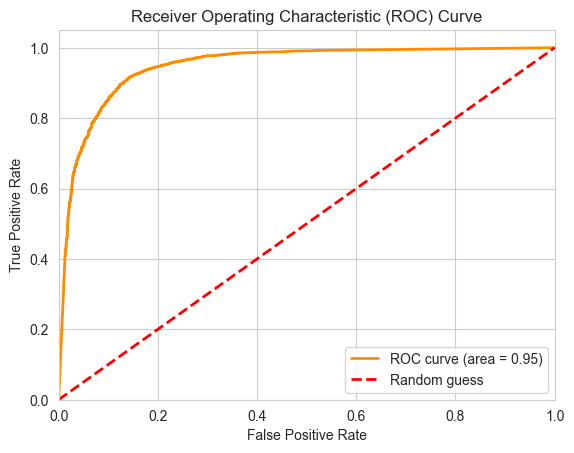

In [140]:
# Evaluate the best KNN model on the validation set
best_knn_model = knn_grid_search.best_estimator_
y_val_pred_knn = best_knn_model.predict(X_val)
y_val_pred_proba_knn = best_knn_model.predict_proba(X_val)[:, 1]

val_accuracy_knn = accuracy_score(y_val, y_val_pred_knn)
val_precision_knn = precision_score(y_val, y_val_pred_knn)
val_recall_knn = recall_score(y_val, y_val_pred_knn)
val_f1_knn = f1_score(y_val, y_val_pred_knn)
val_roc_auc_knn = roc_auc_score(y_val, y_val_pred_proba_knn)

print("K-Nearest Neighbors (KNN) Metrics:")
print(f'Validation Accuracy: {val_accuracy_knn:.5f}')
print(f'Validation Precision: {val_precision_knn:.5f}')  
print(f'Validation Recall: {val_recall_knn:.5f}')  
print(f'Validation F1 Score: {val_f1_knn:.5f}')  
print(f'Validation ROC AUC: {val_roc_auc_knn:.5f}')

# Plot the ROC curve
fpr, tpr, thresholds = roc_curve(y_val, y_val_pred_proba_knn)
roc_auc = roc_auc_score(y_val, y_val_pred_proba_knn)

plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')  
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--', label='Random guess')  
plt.xlim([0.0, 1.0])  
plt.ylim([0.0, 1.05])  
plt.xlabel('False Positive Rate')  
plt.ylabel('True Positive Rate')  
plt.title('Receiver Operating Characteristic (ROC) Curve')  
plt.legend(loc="lower right")  
plt.grid(True)  
plt.show()

Decision Tree Classifier Validation Metrics:
Validation Accuracy: 0.87746
Validation Precision: 0.90999
Validation Recall: 0.83603
Validation F1 Score: 0.87144
Validation ROC AUC: 0.95044
Training Set Metrics:
Training Accuracy: 0.88384
Training Precision: 0.91851
Training Recall: 0.84077
Training F1 Score: 0.87792
Training ROC AUC: 0.95693


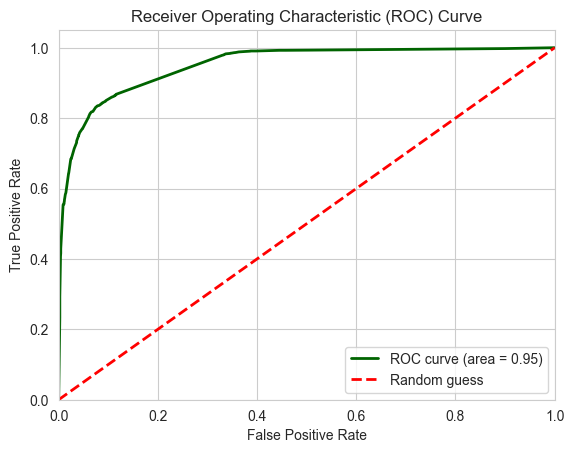

In [ ]:
# Evaluate the best Decision tree model on the validation set
# Predict on the validation set
best_dt_model = dt_grid_search.best_estimator_
y_val_pred_dt = best_dt_model.predict(X_val)
y_val_pred_proba_dt = best_dt_model.predict_proba(X_val)[:, 1]

# Calculate metrics for the validation set
val_accuracy_dt = accuracy_score(y_val, y_val_pred_dt)
val_precision_dt = precision_score(y_val, y_val_pred_dt)  
val_recall_dt = recall_score(y_val, y_val_pred_dt)  
val_f1_dt = f1_score(y_val, y_val_pred_dt)  
val_roc_auc_dt = roc_auc_score(y_val, y_val_pred_proba_dt)  

# Calculate metrics for the training set
y_train_pred_dt= best_dt_model.predict(X_train)  
y_train_pred_proba_dt = best_dt_model.predict_proba(X_train)[:, 1]  

train_accuracy_dt = accuracy_score(y_train, y_train_pred_dt)  
train_precision_dt = precision_score(y_train, y_train_pred_dt)  
train_recall_dt = recall_score(y_train, y_train_pred_dt)  
train_f1_dt = f1_score(y_train, y_train_pred_dt)  
train_roc_auc_dt = roc_auc_score(y_train, y_train_pred_proba_dt)  

print("Decision Tree Classifier Validation Metrics:")
print(f'Validation Accuracy: {val_accuracy_dt:.5f}')
print(f'Validation Precision: {val_precision_dt:.5f}')  
print(f'Validation Recall: {val_recall_dt:.5f}')  
print(f'Validation F1 Score: {val_f1_dt:.5f}')  
print(f'Validation ROC AUC: {val_roc_auc_dt:.5f}')  

print("Training Set Metrics:")
print(f'Training Accuracy: {train_accuracy_dt:.5f}')  
print(f'Training Precision: {train_precision_dt:.5f}')  
print(f'Training Recall: {train_recall_dt:.5f}')  
print(f'Training F1 Score: {train_f1_dt:.5f}')  
print(f'Training ROC AUC: {train_roc_auc_dt:.5f}')

fpr, tpr, thresholds = roc_curve(y_val, y_val_pred_proba_dt)
roc_auc = roc_auc_score(y_val, y_val_pred_proba_dt)

plt.figure()  
plt.plot(fpr, tpr, color='darkgreen', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')  
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--', label='Random guess')  
plt.xlim([0.0, 1.0])  
plt.ylim([0.0, 1.05])  
plt.xlabel('False Positive Rate')  
plt.ylabel('True Positive Rate')  
plt.title('Receiver Operating Characteristic (ROC) Curve')  
plt.legend(loc="lower right")  
plt.grid(True)  
plt.show()